# Practical 1 — Industry Classification from Business-Description Embeddings

**Goal:** given a numeric "fingerprint" (an *embedding*) of a company's business description, predict which of 25 industries the company belongs to.

**How this notebook is organised.** Every section starts with the **questions we should ask ourselves** before touching the code, then the code, then **what we learned**. Where a method is used (PCA, logistic regression, k-NN, F1, McNemar's test) there is a short box with the maths behind it.

| Section | Skeleton task |
|---|---|
| 1. First look at the data | (understanding the data) |
| 2. Train / validation split | Loading Data |
| 3. Label encoding | Transforming Data |
| 4. Class distribution | Visualize the data — over/under-represented classes |
| 5. PCA | Visualize the data — is there signal? |
| 6–8. Two classifiers, metrics, confusion matrices, error overlap | Fitting and comparing classifier models |
| 9. Preview of the bonus metric | Optional part (teaser) |
| 10. Summary | |

In [12]:
import time, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             precision_recall_fscore_support)

RANDOM_STATE = 42

# Plot style: two model colours (blue = logistic regression, orange = k-NN),
# a third accent colour, grey for "everything else", and quiet axes.
C_LR, C_KNN, C_ACCENT, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b7b2"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

def short(name, width=26):
    """Wrap long industry names so they fit in plot titles/ticks."""
    return "\n".join(textwrap.wrap(name, width))

## 1. First look at the data

### Questions to ask ourselves
1. **What is one row?** One company? One description? Can the same company appear twice?
2. **What columns do we have and what are their types?** Which one is the target (what we predict) and which are features (what we predict from)?
3. **Is anything missing?**
4. **What does the embedding actually look like?** Is it already a vector of numbers or text that needs parsing? How many dimensions? What scale are the values on?
5. **How many classes are there?**

***Step 1: Import the libraries and load the data***

In [13]:
import numpy as np
import pandas as pd

df = pd.read_pickle("data/df_train.pkl")

print(df.shape)
df.head()

(31706, 3)


,id,industry,business_description_embedding
38532,42576,Banks,"[0.03411475,-0.03753958,0.023233214,-0.0017205259,-0.004..."
19838,21752,Materials,"[-0.025557408,0.0636078,-0.01350581,-0.018022388,0.02506..."
904,804,Commercial & Professional Services,"[0.033574868,-0.020379327,-0.03221274,-0.01133823,0.0214..."
28806,31603,Insurance,"[0.020648101,0.017270269,-0.032921147,-0.014111616,-0.00..."
10472,11333,Capital Goods,"[-0.0006651232,0.011097765,-0.01976973,0.022994662,-0.02..."


***Step 2:Checking data types and missing values***

In [14]:
print(df.dtypes)
print()
print(df.isna().sum())
print()
print("Number of industries:", df["industry"].nunique())
print()
first = df["business_description_embedding"].iloc[0]
print(type(first))
print(len(first))

id                                 int64
industry                          object
business_description_embedding    object
dtype: object

id                                0
industry                          0
business_description_embedding    0
dtype: int64

Number of industries: 25

<class 'str'>
9476


Missing values: 0 in every column, so nothing is missing and we don’t need to handle empty cells. That’s lucky; real data often has gaps.

25 industries: the model has to pick 1 out of 25 possible answers. This is called multi-class classification (more than two classes). If the model guessed randomly it would be right only 1 in 25 times, which is 4%.

The embedding is a string (<class 'str'>) of 9,476 characters. So it’s not a list of numbers but text that looks like one, e.g. "[0.034,-0.037,0.023,…]". Python can’t do maths with it, because to Python it’s just characters like 0, ., ,. 9,476 is the number of characters, not the number of values. Each number takes about 12 characters (-0.037539580 plus a comma), so we expect roughly 9476 / 12.3 ≈ 770 numbers. We’ll see the exact number in a moment.

***Step 3: Turn the text into real numbers***

In [15]:
import json

X = np.array(df["business_description_embedding"].apply(json.loads).tolist())

print(X.shape)
print(X[0][:5])

(31706, 768)
[ 0.03411475 -0.03753958  0.02323321 -0.00172053 -0.00496361]


31,706 rows means one row per company, the same number as in df. Row 0 of X belongs to row 0 of df, row 1 to row 1, and so on, because apply keeps the order. That’s how we’ll later match features (X) to labels (industry).
768 columns: each company is described by exactly 768 numbers. Our guess of about 770 was close. 768 is a typical size for the output of a language model; each number is one “dimension” of the description’s meaning.

***Step 4: How big are the values, and how long is each vector***

In [16]:
# X.min(), X.max(), X.mean(): the smallest, largest and average value across the whole matrix (all 31,706 × 768 numbers).

print("smallest value:", X.min())
print("largest value: ", X.max())
print("mean:          ", X.mean())

# np.linalg.norm(X, axis=1): computes the length of each company’s vector. axis=1 means “go across each row”, so we get one length per company (31,706 lengths).
# lengths.min(), lengths.max(): the shortest and longest vector.
lengths = np.linalg.norm(X, axis=1)
print("vector length, min:", lengths.min())
print("vector length, max:", lengths.max())

smallest value: -0.22028096
largest value:  0.23074482
mean:           1.1503726109104004e-05
vector length, min: 0.9999998910388799
vector length, max: 1.0000001026570713


The values are all small: between −0.22 and +0.23. Every dimension is on roughly the same scale, so we don’t need to rescale (standardise) the data before modelling
Mean ≈ 0.0000115, which is the scientific notation 1.15e-05, meaning 1.15 × 10⁻⁵. That’s practically 0: positive and negative values balance out.

Every vector has length 1. Min 0.9999999 and max 1.0000001 are both 1 apart from tiny rounding errors in the computer. So the embedding model normalised every vector to length 1 on purpose.

***Step 5:Check for duplicates***

In [17]:
print("duplicate ids:", df["id"].duplicated().sum())

emb = df["business_description_embedding"]
print("rows whose embedding appears more than once:", emb.duplicated(keep=False).sum())

print(emb.value_counts().head(5).values)

duplicate ids: 1
rows whose embedding appears more than once: 4631
[4359  116   19    9    9]


Only one company id is duplicated — but **4,631 rows share their embedding with another row**. Different companies with exactly the same 768 numbers means they had exactly the same description text. Lets take a closer look:

***Step 6: Which industries have the most common embedding***

In [18]:
most_common = emb.value_counts().index[0]

same = df[emb == most_common]
print(len(same))
print(same["industry"].value_counts())

4359
industry
Materials                                       4348
Financial Services                                 2
Technology Hardware & Equipment                    2
Energy                                             2
Equity Real Estate Investment Trusts (REITs)       1
Capital Goods                                      1
Real Estate Management & Development               1
Consumer Durables & Apparel                        1
Transportation                                     1
Name: count, dtype: int64


***Step 7: Mark these “template” rows***

In [19]:
counts = emb.value_counts()
template_embs = counts[counts >= 100].index

df["is_template"] = emb.isin(template_embs)

print(df["is_template"].sum())
print(df.loc[df["is_template"], "industry"].value_counts().head(3))

4475
industry
Materials                               4463
Financial Services                         2
Real Estate Management & Development       2
Name: count, dtype: int64


*** Step 8: Class distribution (how many companies per industry?)***

industry
Materials                                         8394
Capital Goods                                     3127
Financial Services                                1936
Pharmaceuticals, Biotechnology & Life Sciences    1925
Technology Hardware & Equipment                   1547
Software & Services                               1537
Energy                                            1326
Consumer Durables & Apparel                       1164
Food, Beverage & Tobacco                          1094
Health Care Equipment & Services                  1014
Banks                                              948
Media & Entertainment                              915
Real Estate Management & Development               906
Commercial & Professional Services                 804
Consumer Services                                  672
Consumer Discretionary Distribution & Retail       658
Automobiles & Components                           625
Semiconductors & Semiconductor Equipment           607
T

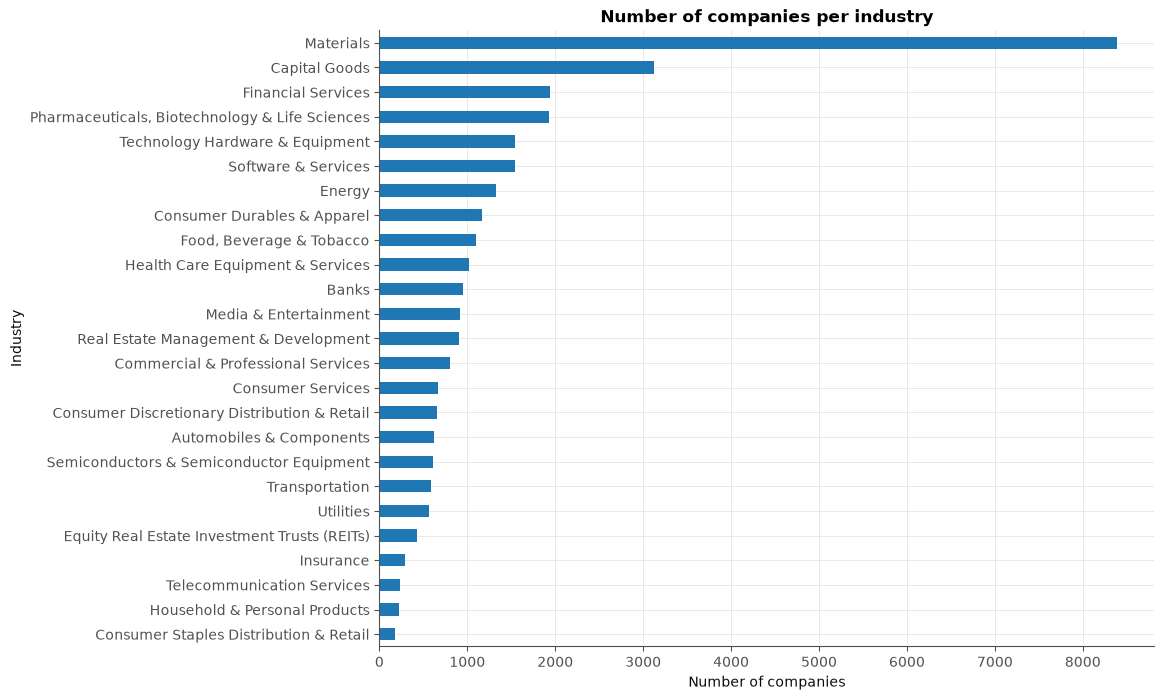

In [20]:
import matplotlib.pyplot as plt

class_counts = df["industry"].value_counts()
print(class_counts)

plt.figure(figsize=(10, 8))
class_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of companies")
plt.ylabel("Industry")
plt.title("Number of companies per industry")
plt.show()

Biggest: Materials with 8,394 companies, 8,394 / 31,706 ≈ 26.5% of all companies, so about 1 in 4 is Materials.

Smallest: Consumer Staples Distribution & Retail (178), then Household & Personal Products (226), Telecommunication Services (230) and Insurance (287). Each of these is below 1% of the data.

How unbalanced? 8,394 / 178 ≈ 47 times bigger. If all 25 industries were the same size, each would have 31,706 / 25 ≈ 1,268 companies. Only 7 industries reach that; 18 of the 25 are below it. So the dataset is strongly imbalanced.

The top 3 (Materials, Capital Goods, Financial Services) together hold 13,457 / 31,706 ≈ 42% of all companies.

The “lazy” model: a model that always says “Materials” would be right 26.5% of the time. That’s our baseline. Any real model has to beat it clearly, otherwise it hasn’t learned anything useful. It’s much higher than random guessing (1/25 = 4%), which shows why plain accuracy can be misleading with imbalanced data.

What imbalance means for us

Big classes: the model sees thousands of examples of Materials, so it will learn them well.
Small classes: for Consumer Staples Retail it only sees about 160 examples, so it will probably do worse there.
Metrics: a model can get high accuracy just by being good at the big classes. That’s why the task also asks for the F1 score, which we’ll look at per industry later.
Template rows: without the 4,463 template rows Materials would have about 3,900 companies. It would still be the biggest class, but much less dominant.

***Step 9: Split into training and validation data***

In [21]:
from sklearn.model_selection import train_test_split

df_train, df_val = train_test_split(df, test_size=0.1, random_state=42)

X_train = X[df.index.get_indexer(df_train.index)]
X_val = X[df.index.get_indexer(df_val.index)]

print(df_train.shape, X_train.shape)
print(df_val.shape, X_val.shape)

(28535, 4) (28535, 768)
(3171, 4) (3171, 768)


Training set: 28,535 companies (90%). Validation set: 3,171 companies (10%). Together that’s 31,706, so no company was lost.

Rows match: df_train and X_train both have 28,535 rows, and df_val and X_val both have 3,171. So features and labels line up.

Why 4 columns and not 3? In Step 7 we added the is_template column. The 4 columns are id, industry, business_description_embedding and is_template. X_train still has 768 columns, because the numbers didn’t change.

Answer to question 2 (small industries). We didn’t stratify the split. Stratifying (stratify=df["industry"]) would force every industry to have exactly the same share in training and validation. Without it the shares can differ a little by chance. For big industries that doesn’t matter. But the smallest one (178 companies) will only have about 18–20 companies in validation, so a single company more or less changes its score by about 5 percentage points. Its score will therefore be noisy. We keep the skeleton’s split anyway, because the instructions use it. We’ll just remember to be careful about drawing conclusions from the smallest industries.

***Step 10: Label encoding (turn industry names into numbers)***

In [22]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(df_train["industry"])

y_train = le.transform(df_train["industry"])
y_val = le.transform(df_val["industry"])

print(le.classes_)
print(y_train[:10])
print(df_train["industry"].values[:3])

missing = set(df_val["industry"]) - set(df_train["industry"])
print("Industries in validation but not in training:", missing)

['Automobiles & Components' 'Banks' 'Capital Goods'
 'Commercial & Professional Services'
 'Consumer Discretionary Distribution & Retail'
 'Consumer Durables & Apparel' 'Consumer Services'
 'Consumer Staples Distribution & Retail' 'Energy'
 'Equity Real Estate Investment Trusts (REITs)' 'Financial Services'
 'Food, Beverage & Tobacco' 'Health Care Equipment & Services'
 'Household & Personal Products' 'Insurance' 'Materials'
 'Media & Entertainment' 'Pharmaceuticals, Biotechnology & Life Sciences'
 'Real Estate Management & Development'
 'Semiconductors & Semiconductor Equipment' 'Software & Services'
 'Technology Hardware & Equipment' 'Telecommunication Services'
 'Transportation' 'Utilities']
[10 21  5 15 12 15 24 17 19 17]
['Financial Services' 'Technology Hardware & Equipment'
 'Consumer Durables & Apparel']
Industries in validation but not in training: set()


le.classes_ lists the 25 industries alphabetically. Each one’s position in the list is its number, counting from 0:

0 = Automobiles & Components
1 = Banks
2 = Capital Goods
…
15 = Materials
…
24 = Utilities

Checking that the encoding matches. The first three labels in y_train are 10, 21, 5:

10 → position 10 in the list is Financial Services ✓
21 → Technology Hardware & Equipment ✓
5 → Consumer Durables & Apparel ✓

These are exactly the three names printed below, so the encoding is correct. You can also see 15 twice in the first 10 labels: that’s Materials, the biggest class, as we’d expect.

set() is Python’s way of printing an empty set. No industry is missing from training, so all 25 can be learned and predicted. ✓

That finishes the skeleton’s “Transforming Data” section. Next is “Visualize the data”: class distribution (done in Step 8) and now PCA.

***Step 11: PCA, shrinking 768 dimensions down to 2***

We can’t plot 768 dimensions. PCA (Principal Component Analysis) finds the directions in which the data spreads out the most, so we can keep the 2 most important ones and plot those.

In [23]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(X_train)

X_train_2d = pca.transform(X_train)

print(X_train_2d.shape)
print(pca.explained_variance_ratio_)
print("together:", pca.explained_variance_ratio_.sum())

(28535, 2)
[0.19296003 0.06101559]
together: 0.25397561864635615


(28535, 2): every training company now has just 2 numbers instead of 768, so we can draw it as a point on a normal x–y plot.

Explained variance:

PC1 keeps 19.3% of the total spread.
PC2 keeps 6.1%.
Together: 25.4%, so about a quarter of the information.

What this means: the 2-D plot shows only a quarter of what’s in the data, and three quarters is lost. So:

If industries look separated in 2-D, they’re definitely different. That’s a strong sign of signal.
If industries overlap in 2-D, that does not prove they overlap in the full 768 dimensions. They may be separated along directions we threw away.

Something suspicious: PC1 (19.3%) is more than 3 times bigger than PC2 (6.1%). One very dominant direction can be a sign of an outlier group. Remember our 4,475 template companies that all sit on (almost) one single point? A big group far from everyone else creates a lot of “spread” in one direction. We’ll see in the plot if that’s what’s happening.

***Step 12: Plot the companies in 2-D, coloured by industry***

With 25 industries, 25 colours would be impossible to tell apart. So we draw all companies in grey and highlight 3 industries that should be very different from each other.

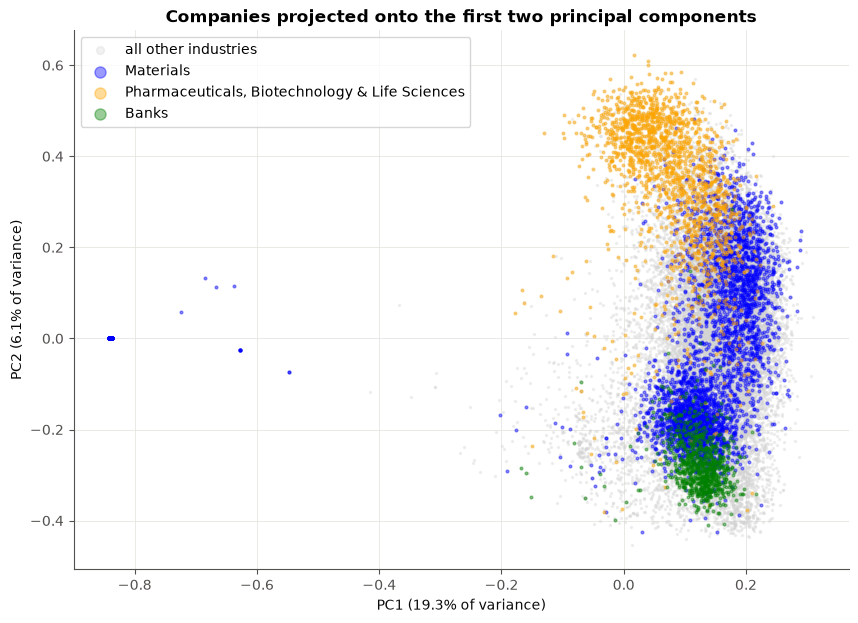

In [ ]:
industries_train = df_train["industry"].values

plt.figure(figsize=(10, 7))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], s=2, c="lightgrey", alpha=0.3, label="all other industries")

for name, color in [("Materials", "blue"), ("Pharmaceuticals, Biotechnology & Life Sciences", "orange"), ("Banks", "green")]:
    mask = industries_train == name
    plt.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], s=4, c=color, alpha=0.4, label=name)

plt.xlabel("PC1 (19.3% of variance)")
plt.ylabel("PC2 (6.1% of variance)")
plt.title("Companies projected onto the first two principal components")
plt.legend(markerscale=4)
plt.show()

1. The strange point on the far left (PC1 ≈ −0.84)
There’s a dense blue dot far away from everything else. That’s our 4,048 training companies with the template embedding, all on exactly the same spot. The few scattered blue dots nearby are the smaller duplicate groups (116, 19, 9, …).

This explains the suspicious number from Step 11: PC1 is mostly measuring “template vs. real description”. Because thousands of identical points sit far away, PCA uses its most important direction to capture that gap. The cost is that all the real companies get squeezed into the narrow strip on the right (PC1 between about −0.1 and 0.3), where it’s harder to see their structure.

2. The three industries sit in different regions

Pharma/Biotech (orange) is mostly at the top (PC2 ≈ 0.3 to 0.6).
Banks (green) form a compact group at the bottom (PC2 ≈ −0.2 to −0.4).
Materials (blue) spreads over the middle and right, and seems to have two parts: one around PC2 ≈ 0.1 and a dense one around PC2 ≈ −0.2.
The grey (all other industries) fills the space in between.

There is overlap: Pharma blends into Materials around PC2 ≈ 0.2, and Banks touch the lower Materials group. But remember, this plot shows only 25% of the information, so some of this overlap may disappear in the full 768 dimensions.

3. Is there signal? Yes. Even with 2 out of 768 dimensions, companies of the same industry clearly gather in the same region. If the embeddings had no industry information, all three colours would be mixed randomly over the whole cloud.

Step 13: PCA again, without the template rows

To see the real structure better, we fit a PCA on the real descriptions only. This is only for the picture: the models will still use all the data.

[0.07509208 0.05616432]


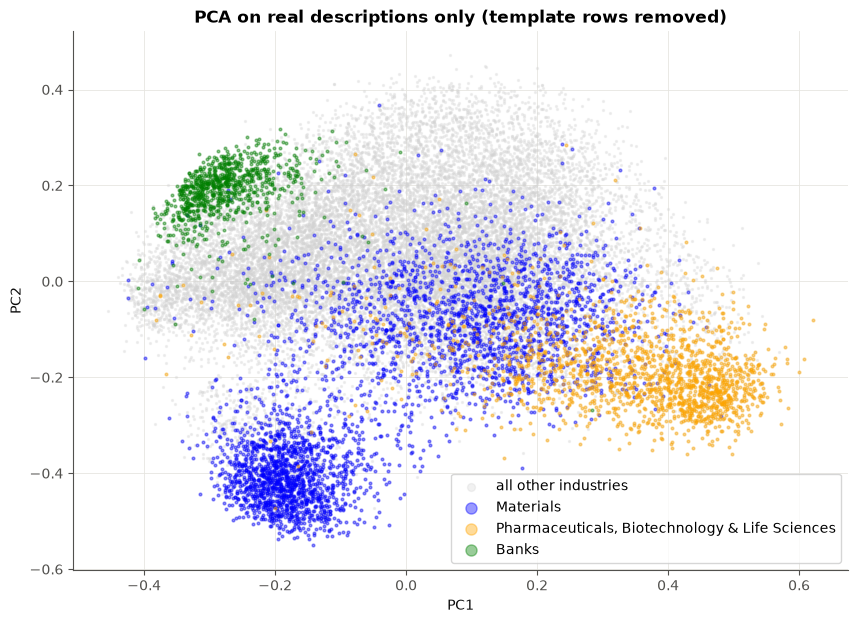

In [25]:
real = ~df_train["is_template"].values

pca_real = PCA(n_components=2)
X_real_2d = pca_real.fit_transform(X_train[real])
industries_real = industries_train[real]

print(pca_real.explained_variance_ratio_)

plt.figure(figsize=(10, 7))
plt.scatter(X_real_2d[:, 0], X_real_2d[:, 1], s=2, c="lightgrey", alpha=0.3, label="all other industries")

for name, color in [("Materials", "blue"), ("Pharmaceuticals, Biotechnology & Life Sciences", "orange"), ("Banks", "green")]:
    mask = industries_real == name
    plt.scatter(X_real_2d[mask, 0], X_real_2d[mask, 1], s=4, c=color, alpha=0.4, label=name)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA on real descriptions only (template rows removed)")
plt.legend(markerscale=4)
plt.show()

What the plot shows

1. PC1 is no longer dominant. It drops from 19.3% to about 7.5%, close to PC2’s 5.6%. This confirms that the big PC1 in the first PCA was mainly caused by the template rows. Now the two main directions describe the real differences between descriptions.

2. The three industries are much better separated

Banks (green) form a tight, compact cluster at the top left. Bank descriptions are very similar to each other (“deposits, loans, branches…”) and different from everything else.
Pharma/Biotech (orange) form a clear cluster on the far right.
Materials (blue) is in the middle and bottom.

Their centres are far apart. That’s a very good sign for classification.

3. Materials has two groups

A dense, compact cluster at the bottom left (around PC1 ≈ −0.2, PC2 ≈ −0.4). This is probably mining and mineral exploration companies. There are many of them (e.g. small gold/lithium explorers in Canada and Australia), and their descriptions sound almost identical.
A wider cloud in the middle, probably chemicals, steel, paper and packaging companies, which are more varied.

So one industry can consist of several distinct groups. That’s useful to know: k-NN, which looks at nearby companies, handles such multi-part industries naturally. A linear model like logistic regression might find it harder, although in 768 dimensions it may still manage.

4. Overlap remains in the centre. The grey cloud (the other 22 industries) is mixed in the middle, and Materials touches Pharma around PC1 ≈ 0.25 (perhaps chemical companies that sound like pharma). With only about 13% of the variance shown, this is expected.

Conclusion for the skeleton question: “Is there signal in the data that allows industry classification?” Yes, clearly. Even in a strongly compressed 2-D view, companies of the same industry gather in their own regions. Some industries (Banks, Pharma, mining-type Materials) are very distinct; others overlap in the centre and will probably be harder to classify.